# Proximity to criticality $d_2$ of the PIF branching network

First application of Sooter's measure (`src.analysis.prox_crit.calc_db`) to the all-to-all probabilistic integrate-and-fire network (`src.models.branching_model`). One small network, one distance to criticality, one estimate - no parameter sweep yet.

Why this should work: the all-to-all PIF is a linear AR(1) process in its conditional mean,
$$E[A_{t+1} \mid A_t] = N\lambda + \sigma_\mathrm{eff} A_t, \qquad \sigma_\mathrm{eff} = (1-\lambda)\sigma = 1 - \epsilon,$$
so the fitted history kernel should be $pprox [1-\epsilon, 0, \dots, 0]$, and we know the ground-truth $d_2$ of that kernel.

In [1]:
%load_ext jupyter_black

import matplotlib.pyplot as plt
import numpy as np

from src.analysis.prox_crit import calc_db, minimize_klr_b
from src.models.branching_model.branching_network import (
    distance_to_criticality,
    params_for_distance,
    pif_aa_population,
    stationary_rate_aa,
    stationary_var_aa,
)
from src.config.paths import FIGURES_DIR

## Simulate a small network

In [2]:
N = 1000  # neurons
T = 20_000  # time steps
rate = 0.1  # target stationary firing probability per neuron and step, a* = E[A]/N
distance = 1e-2  # epsilon = 1 - sigma_eff; relaxation time -1/ln(1 - epsilon) ~ 100 steps

sigma, h = params_for_distance(rate=rate, distance=distance)
# A = ndarray(R=1, T) of int: number of active neurons per step
A = pif_aa_population(N=N, sigma=sigma, T=T, h=h, R=1, seed=0)
activity = A[0]

print(f"sigma = {sigma:.6f}, h = {h:.6f}, epsilon = {distance_to_criticality(sigma, h):.3g}")
print(f"A: shape {A.shape}, dtype {A.dtype}, range [{activity.min()}, {activity.max()}]")
print(f"mean A: {activity.mean():.1f} (theory {stationary_rate_aa(sigma, h) * N:.1f})")
print(f"var  A: {activity.var():.0f} (theory {stationary_var_aa(N, sigma, h):.0f})")
# T / tau ~ 200 independent stretches, so the sample mean deviates from theory by ~ sqrt(var * 2 tau / T) ~ 7 neurons

sigma = 0.990991, h = 0.001001, epsilon = 0.01
A: shape (1, 20000), dtype int64, range [0, 423]
mean A: 108.4 (theory 100.0)
var  A: 4333 (theory 4310)


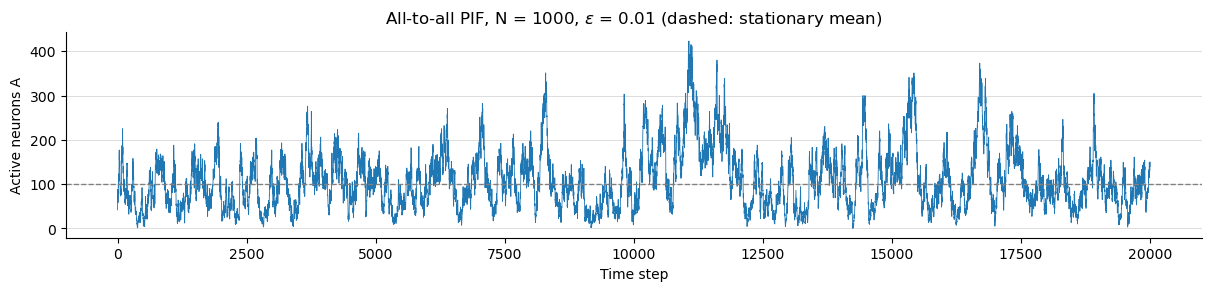

In [3]:
fig, ax = plt.subplots(figsize=(12, 2.8), layout="constrained")
ax.plot(activity, linewidth=0.6, color="tab:blue")
ax.axhline(stationary_rate_aa(sigma, h) * N, color="gray", linewidth=1, linestyle="--")
ax.set(
    xlabel="Time step",
    ylabel="Active neurons A",
    title=rf"All-to-all PIF, N = {N}, $\epsilon$ = {distance:g} (dashed: stationary mean)",
)
ax.grid(axis="y", alpha=0.5, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
# fig.savefig(FIGURES_DIR / "prox_crit_branching_network_activity.png", dpi=150, bbox_inches="tight")

## Estimate $d_2$

Settings as in Sooter's demo: AR order 5, maximum-likelihood fit with error bars, $b = 2$ (distance to the critical manifold with a single root at $z = 1$). The network has no physical time unit, so `delta_t = 1`: $d_2$ is in **bits per time step**.

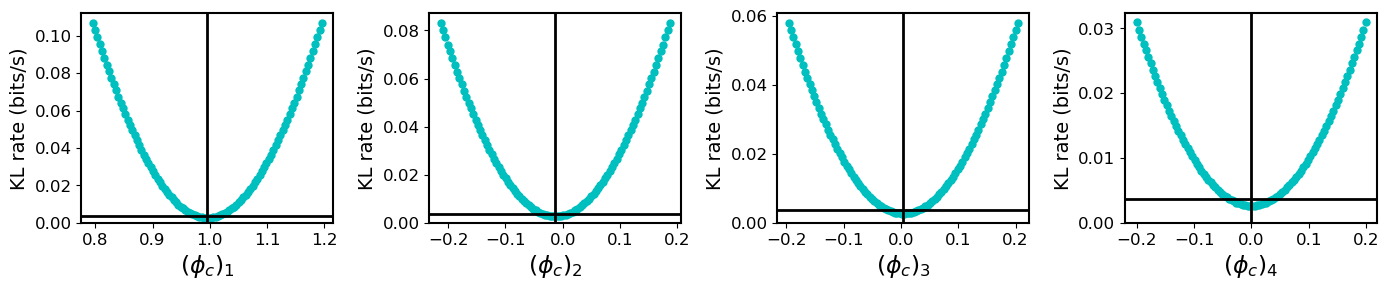

d_2 = 0.00362 +- 0.00036 bits/step, exit status 0
fitted kernel (lags 1..5):  [ 9.908e-01 -1.310e-02  3.700e-03 -5.000e-04  8.600e-03]
closest critical kernel:      [ 9.959e-01 -1.300e-02  3.900e-03 -5.000e-04  1.360e-02]  (sum = 1.0000)
noise std of the fit (z-scored units): 0.1465


In [4]:
order = 5
result = calc_db(
    activity,
    order=order,
    delta_t=1.0,
    b=2,
    fit_method="MaxLikelihood",
    with_err_bars=True,
    with_qc=True,
)
plt.show()

print(f"d_2 = {result.db:.5f} +- {result.sddb.real:.5f} bits/step, exit status {result.exit_status}")
print(f"fitted kernel (lags 1..{order}):  {np.round(result.kern, 4)}")
print(f"closest critical kernel:      {np.round(result.kernc, 4)}  (sum = {result.kernc.sum():.4f})")
print(f"noise std of the fit (z-scored units): {result.sigma:.4f}")
# Lag 1 carries everything (~ 1 - epsilon), lags 2-5 are ~ 0, as expected for an AR(1) process.
# QC plot: the minima sit on the vertical lines (optimum found). The curves dip ~25% below the d_2 line because the plot integrates with trapz (FLAG[6]); this gap grows close to criticality. Its y-label says bits/s, here bits/step.

## Compare with the ground truth

The true kernel is $[1 - \epsilon, 0, 0, 0, 0]$. `minimize_klr_b` gives its exact $d_2$ (in nats/step) without any fitting, so the only difference to the estimate above is finite-sample error of the AR fit.

For order 1 there is a closed form. The KL rate between Gaussian processes with spectra $S_p, S_q$ is $\frac{1}{4\pi}\int (r - 1 - \ln r)\,d\omega$ with $r = S_p/S_q$. Against the random walk ($\phi_c = 1$, free noise ratio $s = \sigma^2/\sigma_c^2$), the log terms integrate to $-2\pi \ln s$ and the spectral mean of $r$ is $2s/(1+\phi)$. Minimizing over $s$ gives $s = (1+\phi)/2$ and
$$d_2^{\mathrm{AR}(1)} = -\tfrac{1}{2}\log_2\left(1 - \tfrac{\epsilon}{2}\right) \approx \frac{\epsilon}{4 \ln 2} \ \text{bits/step}.$$
With order 5 the critical manifold has more freedom, so $d_2$ of the same process is slightly smaller.

In [5]:
true_kernel = np.r_[1 - distance, np.zeros(order - 1)]
db_true_nats, closest_true, exit_flag = minimize_klr_b(true_kernel, b=2)
db_true = db_true_nats / np.log(2)  # nats -> bits

print(f"ground truth d_2 = {db_true:.5f} bits/step (exit flag {exit_flag})")
print(f"estimate - truth = {result.db - db_true:+.5f} bits/step = {(result.db - db_true) / result.sddb.real:+.2f} error bars")

db_closed_form = -0.5 * np.log2(1 - distance / 2)  # AR(1) vs random walk, see above
db_order_1 = minimize_klr_b(true_kernel[:1], b=2)[0] / np.log(2)
print(f"order 1: closed form {db_closed_form:.6f}, minimize_klr_b {db_order_1:.6f} bits/step")
# The estimate lies within its error bar of the truth, and the order-1 numerics reproduce the closed form.
# d_2 ~ epsilon / (4 ln 2) is linear in epsilon for small epsilon (0.0036 bits/step at epsilon = 0.01).

ground truth d_2 = 0.00354 bits/step (exit flag 0)
estimate - truth = +0.00008 bits/step = +0.22 error bars
order 1: closed form 0.003616, minimize_klr_b 0.003616 bits/step
